In [3]:
import ethnohack.cox_model.cox_model_api as cox
import ethnohack.explainer as xai

In [4]:
dataset = cox.load_dataset()

In [5]:
data = cox.clean_data(dataset, smiles_col="Smiles", label_col="Activity")
data = cox.add_scaffolds(data)

Unparsable SMILES removed: 0
Compounds: 4520 | actives: 2492
(55.1%)


In [6]:
# settings
SPLIT_MODE = "scaffold"  # "scaffold" = honest, "random" = optimistic, "both" = run both and compare
N_TRIALS = 30  # Optuna trials; lower = faster
TIMEOUT_MIN = 15  # hard stop for the search

results = cox.run_models(data, SPLIT_MODE, n_trials=N_TRIALS, timeout_min=TIMEOUT_MIN)
result = results[-1]


SPLIT: SCAFFOLD   FEATURES: ecfp
train: 3610 | test: 910 | scaffold overlap: 0


Best trial: 18. Best value: 0.788418: 100%|██████████| 30/30 [10:32<00:00, 21.10s/it, 632.96/900 seconds]


Best CV PR-AUC: 0.788 | params: {'n_estimators': 600, 'max_depth': 35, 'min_samples_leaf': 1, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': 'balanced'}

Prevalence (random-guess PR-AUC): 0.552
PR-AUC   : 0.809
ROC-AUC  : 0.774
MCC      : 0.391
Precision: 0.721
Recall   : 0.745
F1       : 0.733


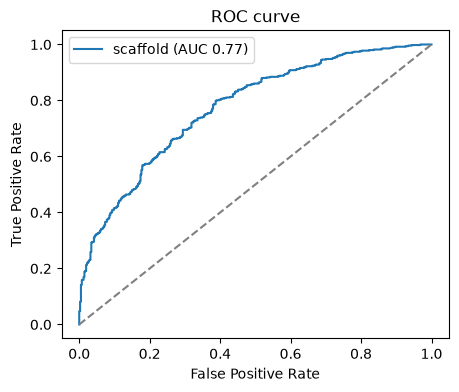

Saved: /home/jenna/workspace/ethnohack/src/ethnohack/cox_model/cox_model.joblib


In [7]:
cox.plot_roc(results)
cox.save_model(result)

Explanation stuff: actually the model is just mildly better than baseline, as the signal mostly stems from the structure itself, it basically performs just as well as basic Similarity Search, but might be computationally more efficient

In [8]:
# nearest-active-neighbour baseline
sim_to_active = cox.similarity_baseline(result)

Similarity baseline ROC-AUC: 0.76
Similarity baseline PR-AUC : 0.792
Your model      ROC-AUC: 0.774
Your model      PR-AUC : 0.809


In [9]:
combo = cox.combined_baseline(result, sim_to_active)

Combined ROC-AUC: 0.785
Combined PR-AUC : 0.82


## Explainable AI (TreeSHAP)
SHAP splits each prediction into contributions of the individual fingerprint bits. Positive values push toward active, negative toward inactive.

In [10]:
model = result["model"]
X_te = cox.featurize(result["test_df"]["smiles"])

# readable names for the 2048 bits (one example substructure per bit) for the SHAP plots
feature_names = cox.bit_names(result["train_df"]["smiles"])

### Global view: which bits drive the model across the test set

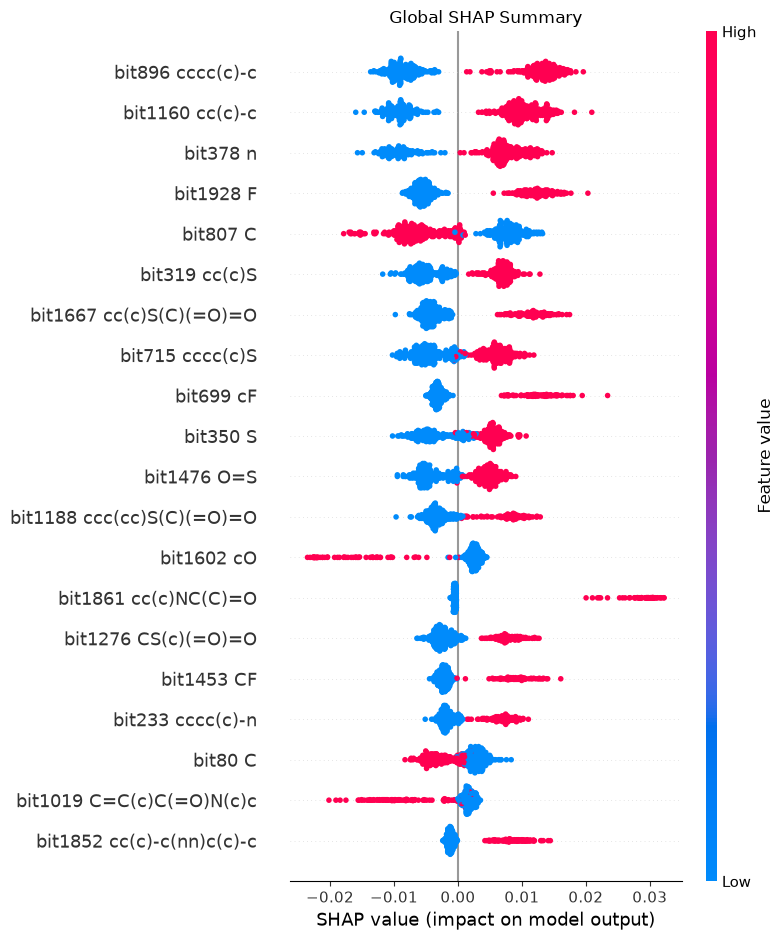

In [11]:
# SHAP values for the active class (subsampled for speed)
shap_matrix, X_shap = xai.global_shap(model, X_te, target_class=1)
xai.plot_global_shap(shap_matrix, X_shap, feature_names)

In [12]:
top_bits = xai.top_bits_table(shap_matrix, X_shap, feature_names)
top_bits

,bit,feature,mean_abs_shap,mean_shap_when_present,pushes_toward,share_of_molecules
0,896,bit896 cccc(c)-c,0.010844,0.013143,active,0.492
1,1160,bit1160 cc(c)-c,0.009903,0.010377,active,0.628
2,378,bit378 n,0.008331,0.007949,active,0.690
3,1928,bit1928 F,0.007871,0.012355,active,0.340
4,807,bit807 C,0.006909,-0.006178,inactive,0.596
5,319,bit319 cc(c)S,0.005828,0.006944,active,0.442
6,1667,bit1667 cc(c)S(C)(=O)=O,0.005783,0.011613,active,0.218
7,715,bit715 cccc(c)S,0.005115,0.006028,active,0.436
8,699,bit699 cF,0.004931,0.012597,active,0.188
9,350,bit350 S,0.004662,0.005375,active,0.476


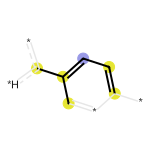

In [13]:
# most important bit drawn as a substructure on a test molecule
xai.highlight_bit(top_bits["bit"].iloc[0], X_te, result["test_df"]["smiles"])

### Local view: why the model predicts what it predicts for single molecules

In [14]:
# most confident hits and mistakes from the test set
examples = xai.select_examples(result)

# reliability check: in_domain = similar enough to the training set to trust the prediction
cox.predict([smiles for smiles, _, _ in examples.values()])

,smiles,proba,active,max_sim_train,in_domain
0,Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(F)(...,0.986046,1.0,1.000000,True
1,COc1ccc(/C=C/C(=O)O[C@H]2[C@H](O[C@H]3[C@H](O)...,0.008447,0.0,0.992188,True
2,Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(C)(...,0.932858,1.0,0.855072,True
3,CC(=O)NCCc1cc(O)c(O)cc1C(=O)c1ccc(O)c(O)c1,0.166265,0.0,0.520000,True



##### True active (most confident) | true label: 1 | model probability: 0.986
SMILES: Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(F)(F)F)c2)cc1)C1CCCC1
Base value: 0.501 | Model probability: 0.986
=== Overlaying Top 4 Present Features ===
Bit ID: 1861| SHAP: +0.028809| Active (+)
Bit ID:  604| SHAP: +0.023991| Active (+)
Bit ID: 1325| SHAP: -0.000957| Inactive (-)
Bit ID: 1057| SHAP: -0.000029| Inactive (-)


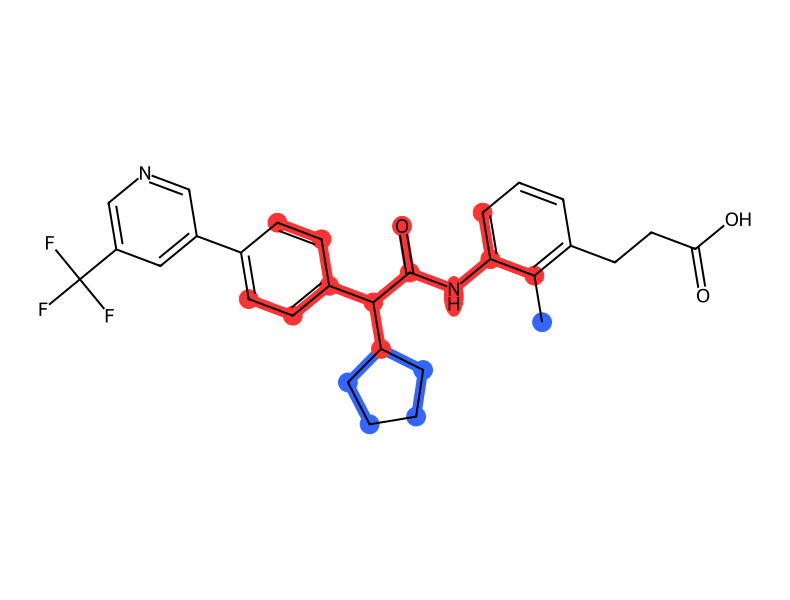

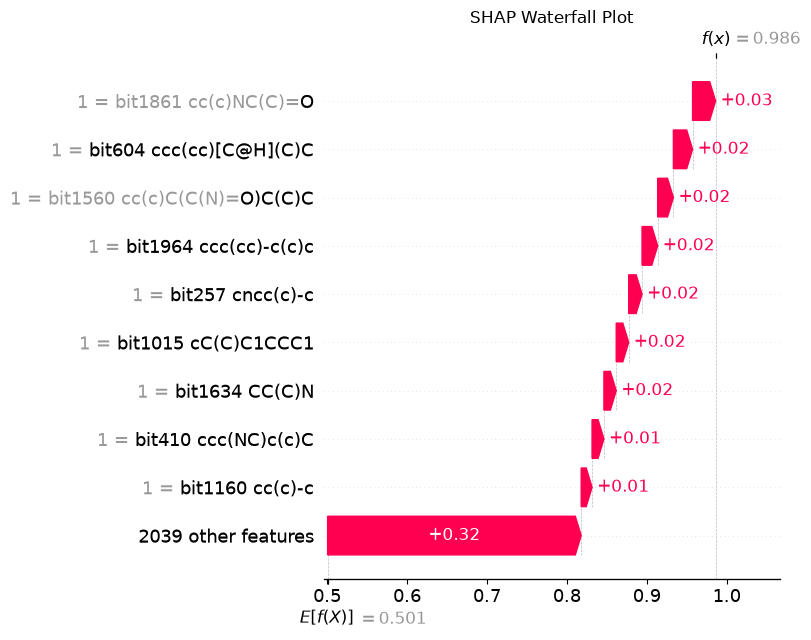


##### True inactive (most confident) | true label: 0 | model probability: 0.008
SMILES: COc1ccc(/C=C/C(=O)O[C@H]2[C@H](O[C@H]3[C@H](O)[C@@H](O)[C@H](O[C@@H]4CO[C@@H](O[C@@H]5[C@@H](O)[C@H](C)O[C@@H](O[C@H]6[C@H](O[C@H]7CC[C@@]8(C)[C@@H](CC[C@]9(C)[C@@H]8CC=C8[C@@H]%10CC(C)(C)CC[C@]%10(C(=O)O[C@@H]%10O[C@H](CO[C@@H]%11O[C@H](CO)[C@@H](O[C@@H]%12O[C@@H](C)[C@H](O)[C@@H](O)[C@H]%12O)[C@H](O)[C@H]%11O)[C@@H](O)[C@H](O)[C@H]%10O)CC[C@]89C)[C@]7(C)CO)OC[C@@H](O)[C@@H]6O)[C@@H]5O)[C@H](O)[C@@H]4O)O[C@@H]3CO)O[C@H](CO)[C@@H](O)[C@@H]2O[C@@H]2O[C@H](CO[C@@H]3O[C@@H](C)[C@H](O)[C@@H](O)[C@H]3O)[C@@H](O[C@@H]3O[C@H](CO)[C@@H](O)[C@H](O)[C@H]3O)[C@H](O)[C@H]2O)cc1O
Base value: 0.501 | Model probability: 0.008
=== Overlaying Top 4 Present Features ===
Bit ID: 1962| SHAP: -0.017318| Inactive (-)
Bit ID:  679| SHAP: -0.016043| Inactive (-)
Bit ID: 1037| SHAP: +0.003129| Active (+)
Bit ID: 1984| SHAP: +0.003053| Active (+)


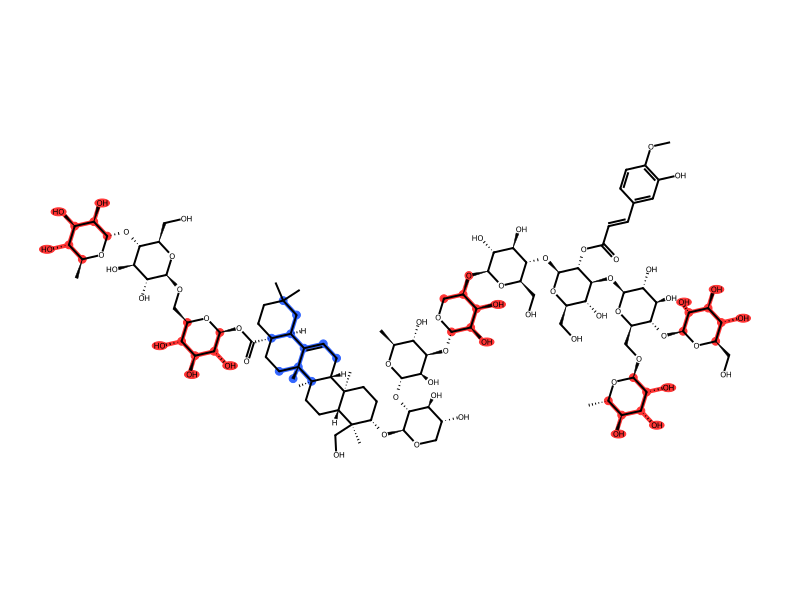

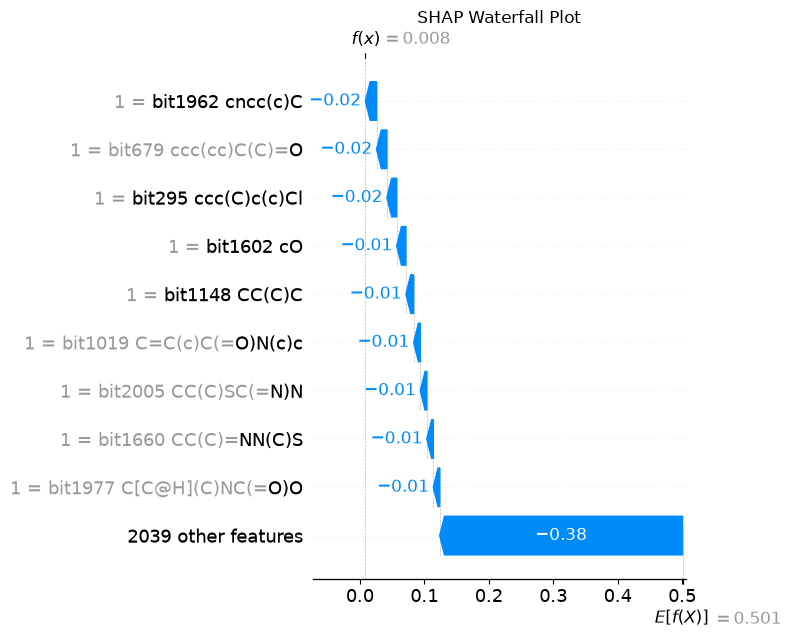


##### False positive (inactive predicted active) | true label: 0 | model probability: 0.933
SMILES: Cc1c(CCC(=O)O)cccc1NC(=O)C(c1ccc(-c2cncc(C(C)(C)O)c2)cc1)C1CCCC1
Base value: 0.501 | Model probability: 0.933
=== Overlaying Top 4 Present Features ===
Bit ID: 1861| SHAP: +0.029212| Active (+)
Bit ID:  604| SHAP: +0.026523| Active (+)
Bit ID: 1218| SHAP: -0.007207| Inactive (-)
Bit ID:  392| SHAP: -0.004346| Inactive (-)


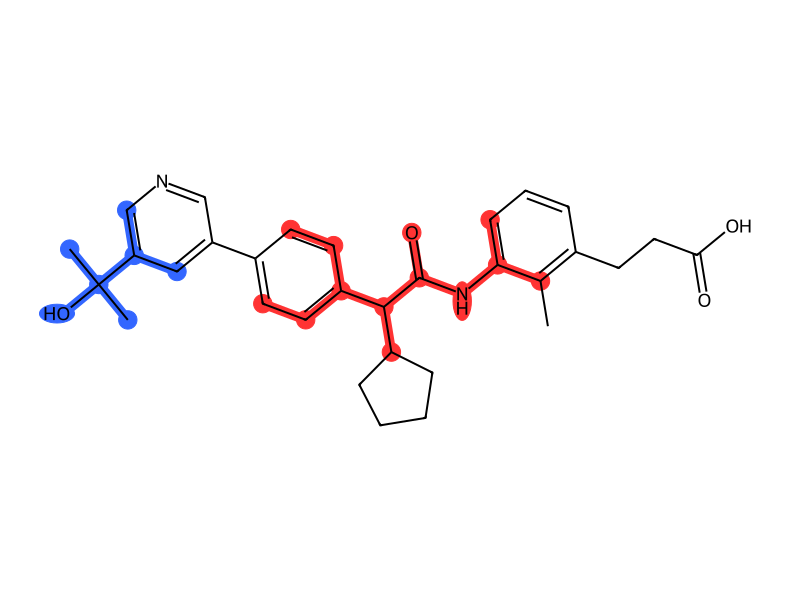

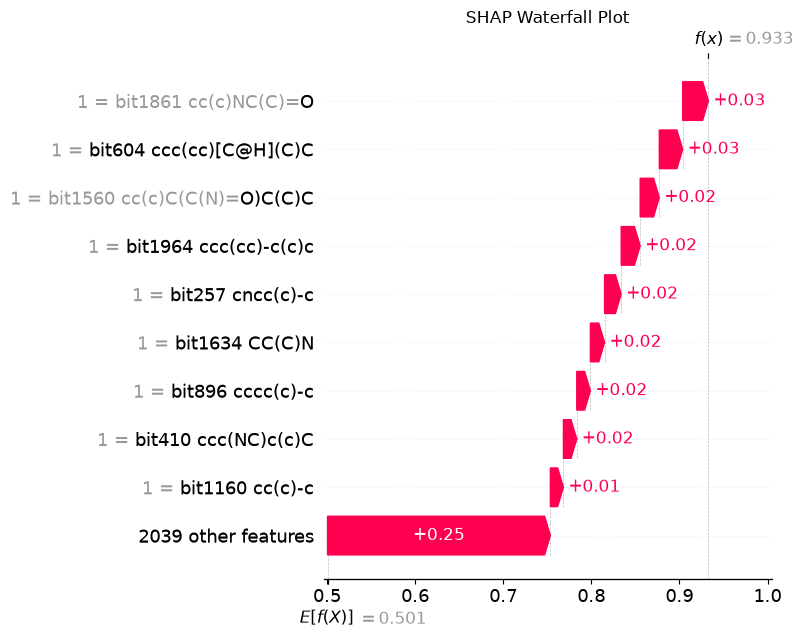


##### False negative (active predicted inactive) | true label: 1 | model probability: 0.166
SMILES: CC(=O)NCCc1cc(O)c(O)cc1C(=O)c1ccc(O)c(O)c1
Base value: 0.501 | Model probability: 0.166
=== Overlaying Top 4 Present Features ===
Bit ID:  589| SHAP: -0.029944| Inactive (-)
Bit ID:  315| SHAP: -0.022738| Inactive (-)
Bit ID: 1110| SHAP: +0.002762| Active (+)
Bit ID:    9| SHAP: +0.002700| Active (+)


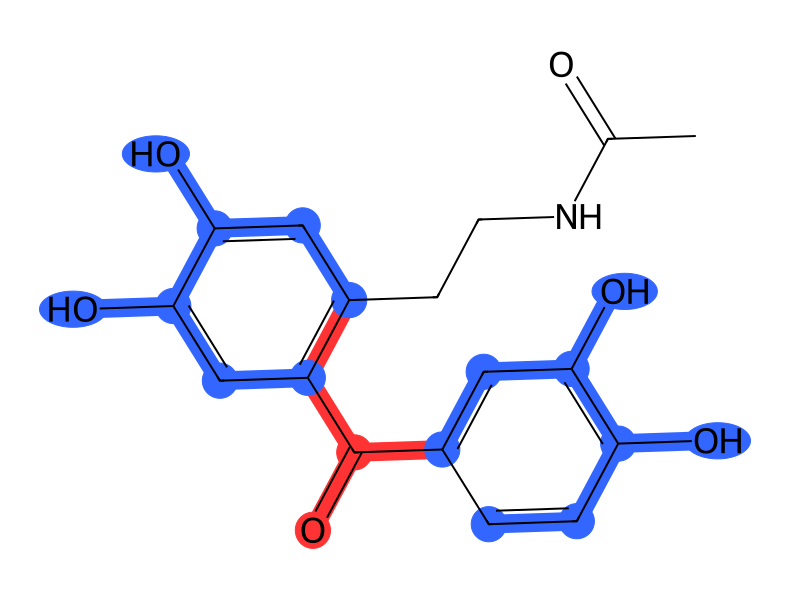

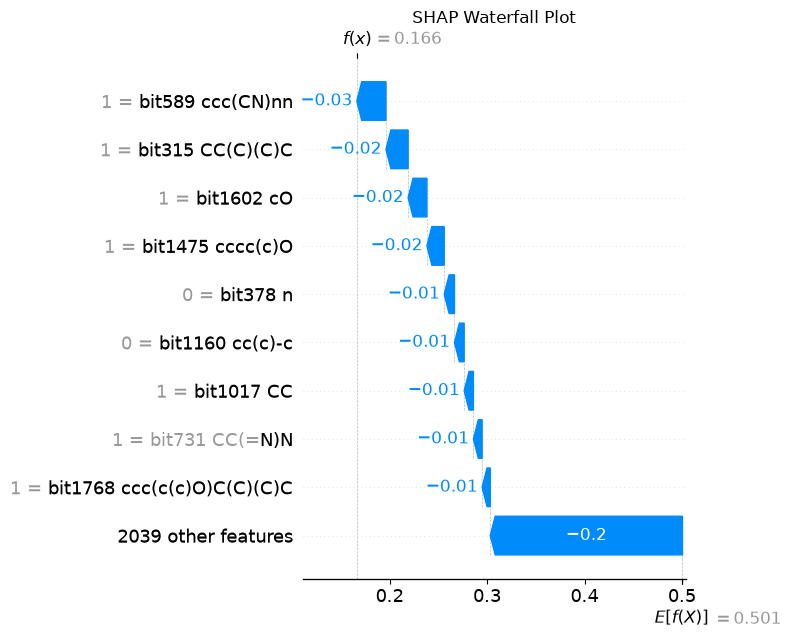

In [15]:
for name, (smiles, proba, label) in examples.items():
    print(f"\n##### {name} | true label: {label} | model probability: {proba:.3f}")
    xai.explain_molecule(smiles, model, target_class=1, feature_names=feature_names)